# XGBoost: búsqueda de hiperparámetros con Optuna (Fase 3)

El problema es predecir el consumo de frío del día siguiente. Esta primera etapa busca configuraciones prometedoras de XGBoost usando exclusivamente los pliegues temporales del entrenamiento. Los resultados son provisionales: el entrenamiento definitivo, la evaluación independiente en validación y la prueba quedan para una etapa posterior.

Actualización de selección (14/11/2026): el conjunto vigente tiene 15 predictoras al incorporar manualmente `es_fin_de_anio` (ADR 0015). Las salidas y métricas guardadas en esta notebook corresponden a las 14 variables originales; se conservan sin reejecución y deberán revisarse para la nueva selección.


## 1. Datos y alcance

Reutilizamos el cargador común y conservamos únicamente su tramo de entrenamiento. Las entradas son las 14 variables de la Fase 2 en sus unidades originales y con sus faltantes: XGBoost los trata de forma nativa, sin imputación ni escalado. El cargador común también construye el tramo de validación por su contrato, pero esta búsqueda no consulta sus valores ni carga el tramo de prueba. Los índices originales identifican las filas porque las fechas pueden repetirse. La tabla 1 describe solamente entrenamiento.

In [1]:
import sys
from pathlib import Path
import json
import zipfile
import hashlib
import importlib.metadata

import numpy as np
import pandas as pd
import optuna
from IPython.display import display

RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
from auxiliar_functions import SEMILLA, tabla_simple
from modelado_comun import (filas_comunes, evaluar_baselines, validacion_cruzada_temporal,
                            calcular_metricas, RUTA_LOG)
from modelado_xgboost import (cargar_entrenamiento, ESPACIO, PARAMS_FIJOS, CONFIG_PRUNER,
                              NOMBRE_ESTUDIO, RUTA_ESTUDIO, configuracion)

entrenamiento = cargar_entrenamiento()
print("Tabla 1. Datos de entrenamiento utilizados en la búsqueda")
display(tabla_simple(pd.DataFrame([{
    "Filas": len(entrenamiento["X"]), "Variables": entrenamiento["X"].shape[1],
    "Filas comunes": int(filas_comunes(entrenamiento).sum()),
    "Primera fecha": entrenamiento["fechas"].min().date().isoformat(),
    "Última fecha": entrenamiento["fechas"].max().date().isoformat(),
    "Valores faltantes en X": int(entrenamiento["X"].isna().sum().sum())
}])))

Tabla 1. Datos de entrenamiento utilizados en la búsqueda


,Filas,Variables,Filas comunes,Primera fecha,Última fecha,Valores faltantes en X
0,830,14,813,2020-07-01,2022-10-27,165


## 2. Validación cruzada temporal

Usamos los cinco pliegues de `validacion_cruzada_temporal`, basados en `TimeSeriesSplit` con `gap=1`. Cada ajuste ve solo la historia previa y deja una fila de separación para evitar el solapamiento inmediato del objetivo del día siguiente. Conservamos todas las filas de ajuste con objetivo y evaluamos solo donde existen objetivo y ambos baselines. La tabla 2 permite comprobar el orden y muestra las referencias de cada período, sin consultar la validación independiente.

In [2]:
filas = []
for paso, (ajuste, evaluacion) in enumerate(validacion_cruzada_temporal().split(entrenamiento["X"])):
    parte = {k: v.iloc[evaluacion] for k, v in entrenamiento.items()}
    filas.append({"Paso": paso, "Filas de ajuste": len(ajuste), "Filas de evaluación": len(evaluacion),
                  "Última fecha de ajuste": entrenamiento["fechas"].iloc[ajuste].max().date().isoformat(),
                  "Primera fecha de evaluación": parte["fechas"].min().date().isoformat(),
                  **evaluar_baselines(parte)})
print("Tabla 2. Pliegues cronológicos y MAE de los baselines sobre filas comunes")
display(tabla_simple(pd.DataFrame(filas).set_index("Paso")))

Tabla 2. Pliegues cronológicos y MAE de los baselines sobre filas comunes


,Filas de ajuste,Filas de evaluación,Última fecha de ajuste,Primera fecha de evaluación,filas,persistencia,media_movil
Paso,,,,,,,
0,139,138,2020-11-20,2020-11-22,138,2576.87,2858.93
1,277,138,2021-04-05,2021-04-07,131,3478.95,3301.24
2,415,138,2021-08-28,2021-09-02,137,3240.04,3774.99
3,553,138,2022-01-17,2022-01-19,134,2976.93,3143.01
4,691,138,2022-06-08,2022-06-10,137,3974.88,3805.95


## 3. Espacio de búsqueda y parámetros fijos

Optuna propone exactamente seis hiperparámetros. Las tasas de aprendizaje y los pesos mínimos de hijos recorren órdenes de magnitud, por eso usamos escala logarítmica. La tabla 3 contiene los rangos efectivos del módulo reutilizable. Los parámetros fijos mantienen la regularización acordada, el objetivo de regresión, MAE como métrica, árboles por histogramas y semilla 42; `n_jobs=1` limita los hilos. No usamos early stopping: cada pliegue construye todos los árboles propuestos por `n_estimators`.

In [3]:
print("Tabla 3. Espacio de hiperparámetros propuestos por Optuna")
display(tabla_simple(pd.DataFrame(ESPACIO).T.rename_axis("Hiperparámetro")))
print("Tabla 4. Parámetros fijos de cada modelo temporal")
display(tabla_simple(pd.Series(PARAMS_FIJOS, name="Valor").to_frame()))

Tabla 3. Espacio de hiperparámetros propuestos por Optuna


,tipo,low,high,log
Hiperparámetro,,,,
n_estimators,int,100,2000,nan
learning_rate,float,0.00,0.30,True
max_depth,int,3,10,nan
min_child_weight,float,0.10,10.00,True
subsample,float,0.50,1.00,nan
colsample_bytree,float,0.50,1.00,nan


Tabla 4. Parámetros fijos de cada modelo temporal


,Valor
reg_alpha,0
reg_lambda,1
gamma,0
objective,reg:squarederror
eval_metric,mae
tree_method,hist
random_state,42
n_jobs,1


## 4. Función objetivo, sampler y poda

La implementación está en `src/modelado_xgboost.py`. `crear_objective` recibe solo entrenamiento, propone los seis parámetros y crea un modelo nuevo por pliegue. Reúne predicciones sobre filas comunes y reporta en los pasos 0 a 4 el MAE acumulado: suma de errores absolutos dividida por cantidad total de observaciones, no promedio simple de MAE por pliegue. Al completar todos los pliegues calcula MAE, RMSE y R² conjuntos con `calcular_metricas` y devuelve el MAE.

`TPESampler(seed=42)` orienta propuestas según los resultados anteriores. `MedianPruner` usa los parámetros de la tabla 5: empieza a considerar poda desde el tercer pliegue y requiere cinco trials completos iniciales y al menos tres referencias en el paso. Optuna compara el mejor valor intermedio del trial con la mediana de los trials completos en ese paso; no es una comparación exclusiva del último valor acumulado. Un trial podado conserva su detalle, pero no recibe métricas finales ni una fila de experimento completo.

In [4]:
print("Tabla 5. Configuración de MedianPruner")
display(tabla_simple(pd.Series(CONFIG_PRUNER, name="Valor").to_frame()))
print("Sampler: TPESampler(seed=42). Dirección: minimize. Máximo total: 100. Trials simultáneos: 1.")

Tabla 5. Configuración de MedianPruner


,Valor
n_startup_trials,5
n_warmup_steps,2
interval_steps,1
n_min_trials,3


Sampler: TPESampler(seed=42). Dirección: minimize. Máximo total: 100. Trials simultáneos: 1.


## 5. Carga del estudio persistido y reanudación

Esta notebook consulta resultados: ejecutarla desde cero no inicia trials. Si falta el SQLite local, restaura únicamente el miembro conocido de la copia versionada sin sobrescribir un estudio existente. La ejecución explícita se realiza desde la raíz con `python src/modelado_xgboost.py --total 100`. Ese total incluye trials completos, podados y fallidos previos; no agrega cien nuevos al reanudar.

Antes de continuar, el script verifica configuración, huellas de datos y código, versiones y árbol Git limpio. Recupera el estado aleatorio de TPE reproduciendo las propuestas previas en memoria, sin entrenar de nuevo; si no coinciden, rechaza continuar. Una interrupción abrupta que deje un trial RUNNING exige revisión explícita: no se lo borra ni se lo convierte automáticamente en otro estado. SQLite y las salidas mutables están en `results/optuna/xgboost/`; al terminar, la evidencia reproducible se incorpora a `results/xgboost/`.

In [5]:
if not RUTA_ESTUDIO.exists():
    archivo = RAIZ / "results" / "xgboost" / "estudio.sqlite3.zip"
    if not archivo.exists():
        raise FileNotFoundError("No hay estudio persistido. Ejecutá primero el comando explícito de búsqueda.")
    RUTA_ESTUDIO.parent.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archivo) as copia:
        RUTA_ESTUDIO.write_bytes(copia.read("estudio.sqlite3"))
estudio = optuna.load_study(study_name=NOMBRE_ESTUDIO, storage=f"sqlite:///{RUTA_ESTUDIO.as_posix()}")
trials = pd.DataFrame([{"Trial": t.number, "Estado": t.state.name,
    "Pliegues completados": len(t.user_attrs.get("pliegues", [])),
    **t.params, **t.user_attrs.get("metricas", {}), "Motivo": t.user_attrs.get("motivo", "")}
    for t in estudio.trials])
print("Tabla 6. Resultados y estados de todos los trials (métricas finales solo en COMPLETE)")
with pd.option_context("display.max_rows", 100):
    display(tabla_simple(trials.set_index("Trial")))
print("Tabla 7. Cantidad de trials por estado")
display(tabla_simple(trials.groupby("Estado").size().to_frame("Trials")))

Tabla 6. Resultados y estados de todos los trials (métricas finales solo en COMPLETE)


,Estado,Pliegues completados,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,mae,rmse,r2,Motivo
Trial,,,,,,,,,,,,
0,COMPLETE,5,812,0.23,8,1.58,0.58,0.58,4592.19,6139.24,0.44,
1,COMPLETE,5,210,0.14,7,2.61,0.51,0.98,4437.28,5899.23,0.49,
2,COMPLETE,5,1682,0.00,4,0.23,0.65,0.76,4278.73,5761.62,0.51,
3,COMPLETE,5,921,0.01,7,0.19,0.65,0.68,4350.97,5832.79,0.50,
4,COMPLETE,5,966,0.09,4,1.07,0.80,0.52,4342.69,5681.43,0.52,
5,COMPLETE,5,1254,0.00,3,7.90,0.98,0.90,4083.45,5433.42,0.56,
6,PRUNED,3,679,0.00,8,0.76,0.56,0.75,nan,nan,nan,MedianPruner al completar el pliegue 3
7,PRUNED,3,165,0.18,5,2.11,0.66,0.76,nan,nan,nan,MedianPruner al completar el pliegue 3
8,COMPLETE,5,1139,0.00,10,3.55,0.97,0.95,4162.58,5421.57,0.57,


Tabla 7. Cantidad de trials por estado


,Trials
Estado,
COMPLETE,45
PRUNED,55


## 6. Mejor configuración provisional

Identificamos la configuración con menor MAE conjunto entre los trials completos, sin evaluar validación independiente ni prueba. La tabla 8 se obtiene del estudio ejecutado, por lo que no hay métricas escritas manualmente. La tabla 9 conserva el detalle de sus pliegues para una revisión posterior. Esta identificación no elige un modelo definitivo ni reemplaza el análisis pendiente de estabilidad, sensibilidad y comparación entre algoritmos.

In [6]:
mejor = estudio.best_trial
print("Tabla 8. Configuración provisional con menor MAE de validación cruzada temporal")
display(tabla_simple(pd.DataFrame([{"Trial": mejor.number, **mejor.params, **mejor.user_attrs["metricas"]}])))
print("Tabla 9. Métricas por pliegue de la mejor configuración provisional")
display(tabla_simple(pd.DataFrame(mejor.user_attrs["pliegues"]).set_index("paso")))

Tabla 8. Configuración provisional con menor MAE de validación cruzada temporal


,Trial,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree,mae,rmse,r2
0,88,1258,0.00,4,4.49,0.97,0.97,3986.65,5198.78,0.60


Tabla 9. Métricas por pliegue de la mejor configuración provisional


,filas_ajuste,filas_comunes,ultimo_indice_ajuste,primer_indice_evaluacion,mae,rmse,r2,mae_acumulado
paso,,,,,,,,
0,139,138,138,140,6656.21,7904.00,-0.56,6656.21
1,277,131,276,278,3562.29,4567.48,-0.12,5149.50
2,415,137,414,416,3144.22,4011.47,0.76,4472.85
3,553,134,552,554,2948.46,3563.43,0.71,4094.57
4,691,137,690,692,3561.25,4708.42,0.45,3986.65


## 7. Controles de reproducibilidad

La tabla 10 comprueba el contrato de configuración, los pasos, las métricas conjuntas, el límite total y el registro común. La prueba de reanudación compara además una secuencia dividida en dos ejecuciones contra una corrida continua de TPE. Las versiones congeladas se verificaron con `uv` en un entorno limpio. El log registra el commit real del código ejecutado y excluye sus propias escrituras del control de cambios; la carpeta mutable de Optuna está ignorada y la evidencia final se versiona después de terminar los trials.

In [7]:
log = pd.read_csv(RUTA_LOG)
marca = f"Optuna {NOMBRE_ESTUDIO}; trial="
registros = log.loc[log["notas"].fillna("").str.startswith(marca)]
completos = [t for t in estudio.trials if t.state.name == "COMPLETE"]
controles = pd.Series({
    "Solo las 14 variables, sin auxiliares": entrenamiento["X"].shape[1] == 14 and not
        {"objetivo", "consumo_dia", "baseline_media_movil", "DIA", "tramo"}.intersection(entrenamiento["X"].columns),
    "Configuración y huellas coinciden": estudio.user_attrs["configuracion"] == configuracion(),
    "Semilla compartida igual a 42": SEMILLA == PARAMS_FIJOS["random_state"] == 42,
    "Máximo total respetado": 0 < len(estudio.trials) <= 100,
    "Todos los trials terminaron": all(t.state.is_finished() for t in estudio.trials),
    "COMPLETE tiene cinco reportes y cinco pliegues": all(list(t.intermediate_values) == list(range(5)) and
        len(t.user_attrs["pliegues"]) == 5 for t in completos),
    "PRUNED y FAIL sin métricas finales": all("metricas" not in t.user_attrs for t in estudio.trials if t.state.name != "COMPLETE"),
    "Métricas agregadas reproducibles": all(np.allclose(list(calcular_metricas(
        t.user_attrs["predicciones"]["real"], t.user_attrs["predicciones"]["predicho"]).values()),
        list(t.user_attrs["metricas"].values())) for t in completos),
    "Una fila de log por trial completo": len(registros) == len(completos) and registros["notas"].is_unique,
    "Log del entrenamiento, con commit y árbol limpio": len(registros) > 0 and
        registros["tramo"].eq("entrenamiento").all() and registros["commit"].eq(estudio.user_attrs["commit_codigo"]).all()
        and registros["arbol_sin_commitear"].eq(False).all(),
})
print("Tabla 10. Controles de la búsqueda (todos deben ser True)")
display(tabla_simple(controles.to_frame("Cumple")))
assert controles.all(), controles[~controles]
print("Tabla 11. Versiones efectivas del entorno")
display(tabla_simple(pd.Series({p: importlib.metadata.version(p) for p in
    ["optuna", "xgboost", "scikit-learn", "numpy", "pandas"]}, name="Versión").to_frame()))

Tabla 10. Controles de la búsqueda (todos deben ser True)


,Cumple
"Solo las 14 variables, sin auxiliares",True
Configuración y huellas coinciden,True
Semilla compartida igual a 42,True
Máximo total respetado,True
Todos los trials terminaron,True
COMPLETE tiene cinco reportes y cinco pliegues,True
PRUNED y FAIL sin métricas finales,True
Métricas agregadas reproducibles,True
Una fila de log por trial completo,True
"Log del entrenamiento, con commit y árbol limpio",True


Tabla 11. Versiones efectivas del entorno


,Versión
optuna,5.0.0
xgboost,3.4.1
scikit-learn,1.9.1
numpy,2.5.4
pandas,3.0.6


## 8. Conclusión y limitaciones

La búsqueda persistida permite identificar una configuración provisional por MAE temporal y conservar estados, métricas y predicciones de los trials completos. La poda reduce trabajo en configuraciones poco prometedoras, pero deja menos información sobre ellas. La métrica agregada pondera cada observación por igual y los períodos tienen niveles de dificultad distintos.

El análisis exhaustivo de estabilidad de los resultados y de sensibilidad a los hiperparámetros queda pendiente. Las variables ya se seleccionaron en una etapa anterior, por lo que esta validación cruzada no equivale a una evaluación anidada de todo el proceso. Reproducir exactamente requiere mismas versiones, datos y orden secuencial de propuestas; si cambian, se debe abrir otro estudio con identidad distinta. No se entrenó ni serializó un modelo definitivo y no se hizo evaluación independiente en validación ni prueba.

## 9. Evaluación independiente del ganador con 15 predictoras

Esta sección posterior conserva las salidas históricas de la búsqueda original. Recupera el trial ganador del estudio de 15 variables, fija sus hiperparámetros sin consultar validación y ajusta un único XGBoost con las 830 filas de entrenamiento, sin imputación, escalado ni early stopping. Se mide exclusivamente en las 171 filas comunes de validación. No se utiliza prueba ni se prepara un modelo de producción. El módulo registra el commit real, las predicciones y la comparación con los registros ya existentes de Ridge, Lasso y Random Forest con 15 variables y Optuna. Si la evidencia de esta evaluación ya existe, solo la lee y no vuelve a entrenar.

La celda es autónoma para ejecutarla sin repetir las secciones anteriores. Las cifras proceden de los resultados ejecutados; la validación ya intervino en la selección previa de variables y comparar familias añade sesgo de selección.

In [1]:
import sys
from pathlib import Path
import pandas as pd
from IPython.display import display

raiz_evaluacion = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz_evaluacion / "src"))
from auxiliar_functions import tabla_simple
from evaluar_xgboost_15_validacion import evaluar_validacion

evaluacion_15, comparacion_15 = evaluar_validacion()
print("Tabla 12. Evaluación independiente de modelos con 15 predictoras sobre 171 filas comunes")
display(tabla_simple(comparacion_15.set_index("modelo")))
print("Tabla 13. Hiperparámetros del trial ganador, fijados antes de evaluar validación")
display(tabla_simple(pd.Series(evaluacion_15["registro"]["hiperparametros"], name="Configuración").to_frame()))
print("Tabla 14. Controles de alcance y trazabilidad de esta evaluación")
display(tabla_simple(pd.Series({
    "15 predictoras": len(evaluacion_15["predictoras"]) == 15,
    "830 filas de ajuste": evaluacion_15["filas_ajuste"] == 830,
    "171 filas comunes evaluadas": evaluacion_15["filas_evaluacion"] == 171,
    "Árbol limpio al registrar": evaluacion_15["registro"]["arbol_sin_commitear"] is False,
    "Registro de validación": evaluacion_15["registro"]["tramo"] == "validacion",
}, name="Cumple").to_frame()))

Tabla 12. Evaluación independiente de modelos con 15 predictoras sobre 171 filas comunes


,filas,mae,rmse,r2,commit
modelo,,,,,
xgboost,171,2221.76,2844.31,0.46,29597cac53a0b1d5eee69e6da645a48999a01b5b
lasso,171,2265.62,2901.50,0.44,9d5385113e72c00f5d7a3c4bda3375622a04d38c
ridge,171,2284.20,2936.33,0.43,9d5385113e72c00f5d7a3c4bda3375622a04d38c
random_forest,171,2319.08,2987.37,0.41,9d5385113e72c00f5d7a3c4bda3375622a04d38c


Tabla 13. Hiperparámetros del trial ganador, fijados antes de evaluar validación


,Configuración
0,"{""colsample_bytree"": 0.8086142929785466, ""eval_metric"": ""mae"", ""gamma"": 0, ""learning_rate"": 0.0020702351473759497, ""max_depth"": 3, ""min_child_weight"": 4.49480789319248, ""n_estimators"": 1908, ""n_jobs"": 1, ""objective"": ""reg:squarederror"", ""random_state"": 42, ""reg_alpha"": 0, ""reg_lambda"": 1, ""subsample"": 0.9516935603337213, ""tree_method"": ""hist""}"


Tabla 14. Controles de alcance y trazabilidad de esta evaluación


,Cumple
15 predictoras,True
830 filas de ajuste,True
171 filas comunes evaluadas,True
Árbol limpio al registrar,True
Registro de validación,True


### Conclusión de la evaluación independiente

La tabla 12 compara MAE sobre el mismo período y las mismas filas comunes, a diferencia de comparar el MAE cruzado de entrenamiento con el de validación. El modelo se ajustó solo con entrenamiento y los hiperparámetros permanecieron fijados por Optuna. La evaluación no constituye selección ni entrenamiento final para producción; el conjunto de prueba continúa reservado.

## 10. Gráficos del estudio Optuna de 15 predictoras

Esta sección carga exclusivamente el estudio ya guardado `xgboost-temporal-15-features-v1`. Para preservar el SQLite original, la lectura de Optuna se realiza sobre una copia local. Se generan los tres gráficos con la interfaz Matplotlib de Optuna y se exportan en PNG. No se ejecutan búsquedas, entrenamientos de XGBoost ni evaluaciones.

In [1]:
from pathlib import Path
import hashlib
import json
import shutil

import matplotlib.pyplot as plt
import optuna
from optuna.importance import FanovaImportanceEvaluator
from optuna.visualization.matplotlib import (
    plot_param_importances, plot_parallel_coordinate, plot_optimization_history,
)

raiz_graficos = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sqlite_15 = raiz_graficos / "results/optuna/xgboost_15/estudio_15.sqlite3"
resumen_15 = json.loads((raiz_graficos / "results/xgboost_15/resumen.json").read_text(encoding="utf-8"))
if not sqlite_15.exists():
    raise FileNotFoundError("Se requiere el SQLite del estudio guardado de 15 features.")
huella_estudio_antes = hashlib.sha256(sqlite_15.read_bytes()).hexdigest()
copia_graficos = sqlite_15.parent / "lectura_graficos.sqlite3"
shutil.copyfile(sqlite_15, copia_graficos)
estudio_graficos_15 = optuna.load_study(
    study_name=resumen_15["estudio"], storage=f"sqlite:///{copia_graficos.as_posix()}"
)
cantidad_trials_guardados = len(estudio_graficos_15.trials)
carpeta_png_15 = raiz_graficos / "results/xgboost_15/graficos"
carpeta_png_15.mkdir(parents=True, exist_ok=False)
plt.rcParams.update({"font.size": 11, "figure.dpi": 120, "savefig.dpi": 220})

La importancia de hiperparámetros se calcula con `FanovaImportanceEvaluator(seed=42)`, mediante f-ANOVA, y se muestra con `plot_param_importances`. El cálculo utiliza los trials completos del estudio existente. Se conserva el gráfico visible en la notebook y se exporta el mismo contenido a PNG.

C:\Users\juanc\AppData\Local\Temp\ipykernel_26796\925010671.py:1: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  eje_importancias = plot_param_importances(


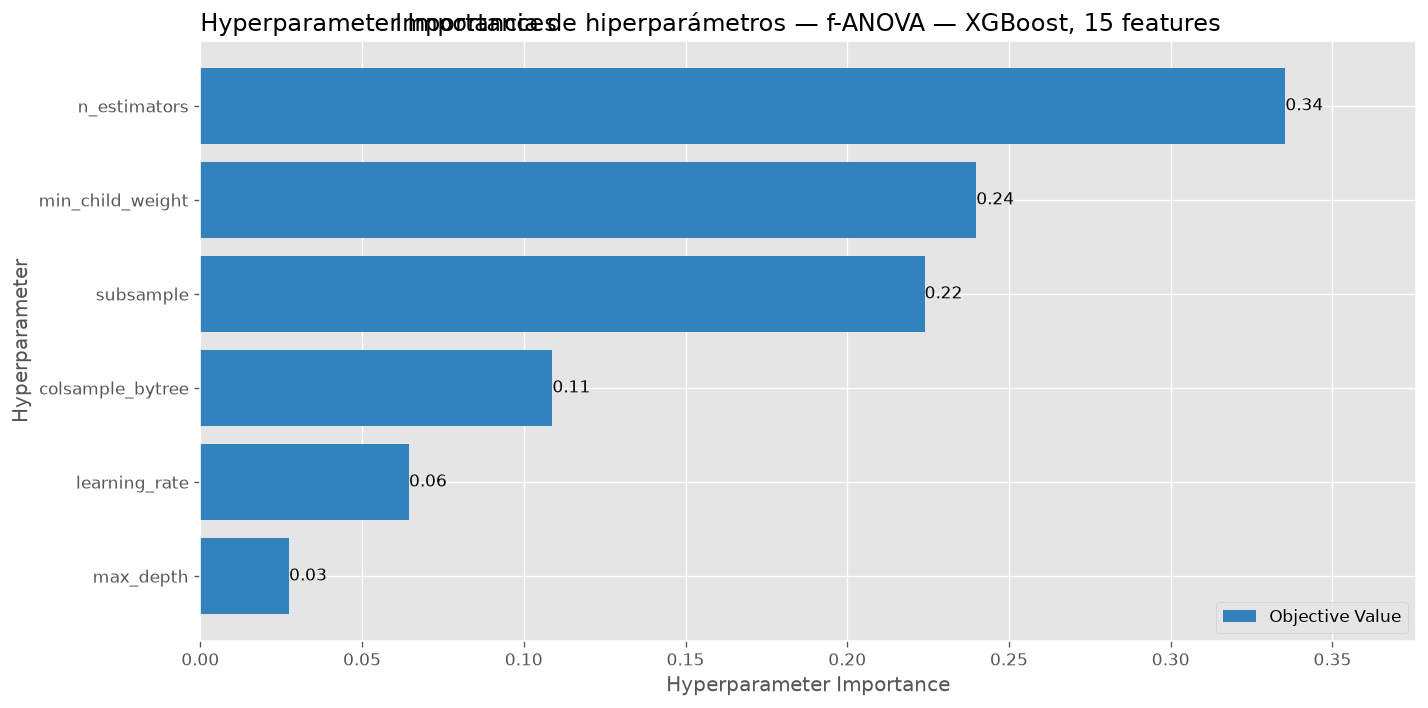

In [2]:
eje_importancias = plot_param_importances(
    estudio_graficos_15, evaluator=FanovaImportanceEvaluator(seed=42)
)
fig_importancias = eje_importancias.figure
fig_importancias.set_size_inches(12, 6)
eje_importancias.set_title("Importancia de hiperparámetros — f-ANOVA — XGBoost, 15 features")
fig_importancias.tight_layout()
fig_importancias.savefig(carpeta_png_15 / "importancia_hiperparametros_fanova.png", bbox_inches="tight", facecolor="white")
plt.show()

El gráfico de coordenadas paralelas se genera con `plot_parallel_coordinate` sobre el mismo estudio de 15 predictoras. Cada eje corresponde a un hiperparámetro o al objetivo MAE. La figura mostrada se guarda también en PNG.

C:\Users\juanc\AppData\Local\Temp\ipykernel_26796\240063882.py:1: ExperimentalWarning: optuna.visualization.matplotlib._parallel_coordinate.plot_parallel_coordinate is experimental (supported from v2.2.0). The interface can change in the future.
  eje_paralelas = plot_parallel_coordinate(estudio_graficos_15)


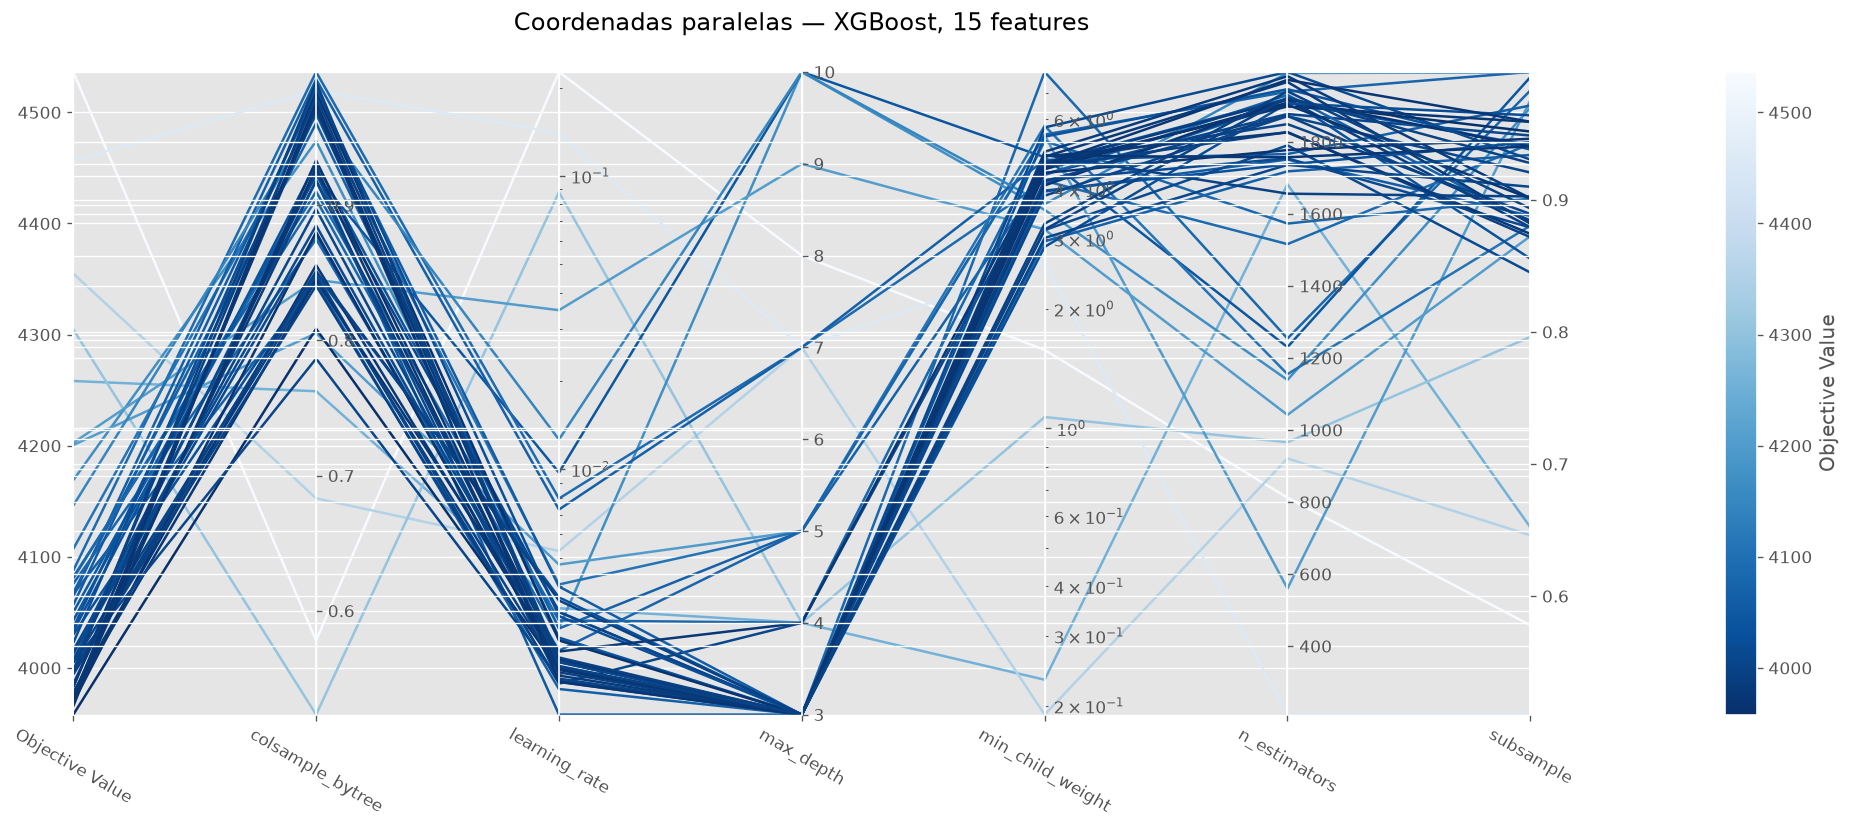

In [3]:
eje_paralelas = plot_parallel_coordinate(estudio_graficos_15)
fig_paralelas = eje_paralelas.figure
fig_paralelas.set_size_inches(17, 7)
eje_paralelas.set_title("Coordenadas paralelas — XGBoost, 15 features", pad=25)
fig_paralelas.tight_layout()
fig_paralelas.savefig(carpeta_png_15 / "coordenadas_paralelas.png", bbox_inches="tight", facecolor="white")
plt.show()

El historial se obtiene con `plot_optimization_history`, sin iniciar ensayos adicionales. Se exporta la figura a PNG y se comprueba que el número de trials y la huella del SQLite original permanezcan iguales a los registrados antes de generar los gráficos.

C:\Users\juanc\AppData\Local\Temp\ipykernel_26796\105869753.py:1: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  eje_historial = plot_optimization_history(estudio_graficos_15)


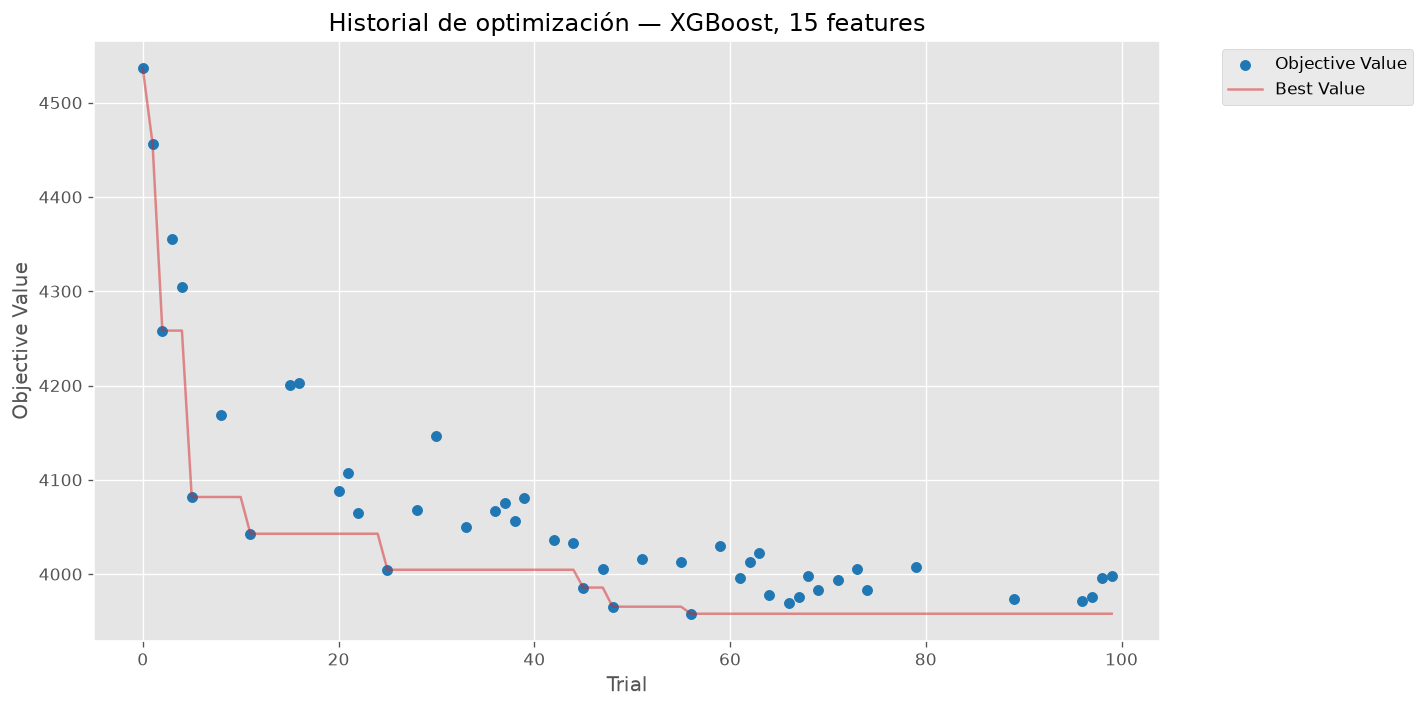

C:\Users\juanc\OneDrive\Documentos\tp_final_lab\modelado-xgboost\results\xgboost_15\graficos\coordenadas_paralelas.png
C:\Users\juanc\OneDrive\Documentos\tp_final_lab\modelado-xgboost\results\xgboost_15\graficos\historial_optimizacion.png
C:\Users\juanc\OneDrive\Documentos\tp_final_lab\modelado-xgboost\results\xgboost_15\graficos\importancia_hiperparametros_fanova.png


In [4]:
eje_historial = plot_optimization_history(estudio_graficos_15)
fig_historial = eje_historial.figure
fig_historial.set_size_inches(12, 6)
eje_historial.set_title("Historial de optimización — XGBoost, 15 features")
fig_historial.tight_layout()
fig_historial.savefig(carpeta_png_15 / "historial_optimizacion.png", bbox_inches="tight", facecolor="white")
plt.show()
if len(estudio_graficos_15.trials) != cantidad_trials_guardados:
    raise RuntimeError("Cambió la cantidad de trials.")
if hashlib.sha256(sqlite_15.read_bytes()).hexdigest() != huella_estudio_antes:
    raise RuntimeError("Cambió el SQLite original.")
for archivo_png in sorted(carpeta_png_15.glob("*.png")):
    print(archivo_png)

## 11. Lectura de los gráficos y definición de una segunda búsqueda

La importancia estimada mediante f-ANOVA concentra aproximadamente 34 % en `n_estimators`, 24 % en `min_child_weight` y 22 % en `subsample`. Estas importancias describen el espacio explorado y las configuraciones completadas; no son efectos causales ni garantizan la importancia fuera de ese espacio. Las coordenadas paralelas sugieren que los menores MAE se concentran en árboles poco profundos y cantidades altas de árboles. El historial mejoró hasta alrededor del ensayo 57 (trial 56, numerado desde cero) y luego se estabilizó cerca de 3.957,96 kW.

Estos resultados justifican explorar una zona más específica, sin afirmar que se encontró el óptimo definitivo. Para elegir los nuevos intervalos se revisan exclusivamente los diez mejores trials completos por MAE temporal de entrenamiento, sin utilizar la evaluación independiente de validación ya disponible.

Los diez mejores tienen `n_estimators` entre 1.757 y 1.982, `min_child_weight` entre 4,09035 y 4,97287, `subsample` entre 0,87423 y 0,95912 y `colsample_bytree` entre 0,80861 y 0,98423. Nueve de ellos usan profundidad 3. Se redondean hacia afuera los intervalos a 1.750–3.000 árboles, peso 4,0–5,0 (logarítmico), muestreo de filas 0,87–0,97 y muestreo de columnas 0,80–1,00. Los árboles se amplían hasta 3.000 porque los mejores valores están concentrados cerca del límite superior previo de 2.000.

Se fijan `learning_rate=0.0020702351473759497` y `max_depth=3`, tomados del mejor trial anterior. La segunda búsqueda tiene 60 trials totales y nombre `xgboost-temporal-15-features-refinado-v1`, con SQLite independiente. Reutiliza `TPESampler(seed=42)`, el mismo `MedianPruner`, cinco pliegues con `gap=1` y el MAE conjunto de las filas comunes. No usa early stopping ni ajusta un modelo definitivo. El ejecutor explícito es `python src/modelado_xgboost_15_refinado.py`; la celda siguiente solo consulta evidencia y no inicia trials.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display
import sys

raiz_refinado = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz_refinado / "src"))
from auxiliar_functions import tabla_simple

carpeta_refinado = raiz_refinado / "results/xgboost_15_refinado"
resumen_refinado = json.loads((carpeta_refinado / "resumen.json").read_text(encoding="utf-8"))
comparacion_refinado = json.loads((carpeta_refinado / "comparacion.json").read_text(encoding="utf-8"))
print("Tabla 15. Los diez mejores trials del estudio previo, usados para definir los intervalos")
display(tabla_simple(pd.read_csv(carpeta_refinado / "top10_estudio_anterior.csv").set_index("trial")))
print("Tabla 16. Rangos optimizados en la segunda búsqueda")
display(tabla_simple(pd.DataFrame(comparacion_refinado["rangos"]).T))
print("Tabla 17. Estados de los 60 trials del estudio refinado")
display(tabla_simple(pd.Series(resumen_refinado["estados"], name="Trials").to_frame()))
print("Tabla 18. Mejores hiperparámetros provisionales y parámetros fijos")
display(tabla_simple(pd.Series({**comparacion_refinado["fijos"], **resumen_refinado["parametros_provisionales"]}, name="Valor").to_frame()))
print("Tabla 19. Comparación de MAE temporal de entrenamiento entre búsquedas")
display(tabla_simple(pd.DataFrame([{
    "MAE anterior": comparacion_refinado["mae_anterior"],
    "MAE nuevo": comparacion_refinado["mae_nuevo"],
    "Diferencia nuevo menos anterior": comparacion_refinado["diferencia_nuevo_menos_anterior"],
    "Mejora (%)": comparacion_refinado["mejora_porcentual"],
}])))
print("El signo de la diferencia indica mejora si es negativo y empeoramiento si es positivo.")

Tabla 15. Los diez mejores trials del estudio previo, usados para definir los intervalos


,mae,n_estimators,learning_rate,max_depth,min_child_weight,subsample,colsample_bytree
trial,,,,,,,
56,3957.96,1908,0.00,3,4.49,0.95,0.81
48,3965.43,1918,0.00,3,4.09,0.94,0.98
66,3968.84,1777,0.00,3,4.40,0.95,0.88
96,3971.92,1903,0.00,3,4.55,0.90,0.93
89,3973.10,1972,0.00,3,4.62,0.96,0.98
67,3975.79,1898,0.00,4,4.61,0.96,0.84
97,3976.03,1757,0.00,3,4.86,0.94,0.93
64,3977.89,1826,0.00,3,4.84,0.87,0.86
69,3982.63,1966,0.00,3,4.83,0.88,0.97


Tabla 16. Rangos optimizados en la segunda búsqueda


,tipo,low,high,log
n_estimators,int,1750,3000,nan
min_child_weight,float,4.00,5.00,True
subsample,float,0.87,0.97,nan
colsample_bytree,float,0.80,1.00,nan


Tabla 17. Estados de los 60 trials del estudio refinado


,Trials
COMPLETE,45
PRUNED,15


Tabla 18. Mejores hiperparámetros provisionales y parámetros fijos


,Valor
reg_alpha,0
reg_lambda,1
gamma,0
objective,reg:squarederror
eval_metric,mae
tree_method,hist
random_state,42
n_jobs,1
learning_rate,0.00
max_depth,3


Tabla 19. Comparación de MAE temporal de entrenamiento entre búsquedas


,MAE anterior,MAE nuevo,Diferencia nuevo menos anterior,Mejora (%)
0,3957.96,3941.22,-16.74,0.42


El signo de la diferencia indica mejora si es negativo y empeoramiento si es positivo.


La comparación anterior corresponde al mismo procedimiento temporal dentro de entrenamiento. Ambos mínimos siguen siendo provisionales: la segunda búsqueda utiliza información de la primera y un presupuesto y espacio distintos, por lo que la diferencia observada no demuestra generalización ni un óptimo global. Las evaluaciones y figuras anteriores se conservan como evidencia histórica.

## 12. Configuración completa y curvas de MAE en validación independiente

Esta sección reemplaza el diagnóstico solicitado inicialmente sobre el último pliegue: ese diagnóstico no se ejecuta. Se fija la configuración completa del ganador de la segunda búsqueda combinando los cuatro parámetros optimizados con todos los parámetros fijos conservados, incluidos `learning_rate` y `max_depth`. Se ajusta un único XGBoost con las 830 filas de entrenamiento y sin early stopping.

Se proporcionan a `eval_set` el entrenamiento completo y las mismas 171 filas comunes de validación independiente. `evals_result()` registra el MAE de ambos conjuntos desde el primer árbol hasta el `n_estimators` elegido por Optuna. La validación no controla el ajuste, la cantidad de árboles ni los hiperparámetros. Se conservan las curvas y las predicciones, se registra la evaluación con el commit real y se exporta el gráfico en PNG. La celda es autónoma y reutiliza la evidencia si ya existe, sin repetir el entrenamiento. No se utiliza prueba ni se entrena un modelo de producción. El gráfico queda sin interpretación sobre sobreajuste.

Tabla 20. Configuración completa de XGBoost fijada antes de evaluar validación


,Valor
reg_alpha,0
reg_lambda,1
gamma,0
objective,reg:squarederror
eval_metric,mae
tree_method,hist
random_state,42
n_jobs,1
learning_rate,0.00
max_depth,3


Tabla 21. MAE de validación independiente del ganador refinado


,Trial,Filas de entrenamiento,Filas comunes de validación,Árboles entrenados,MAE de validación (kW)
0,49,830,171,1994,2229.22


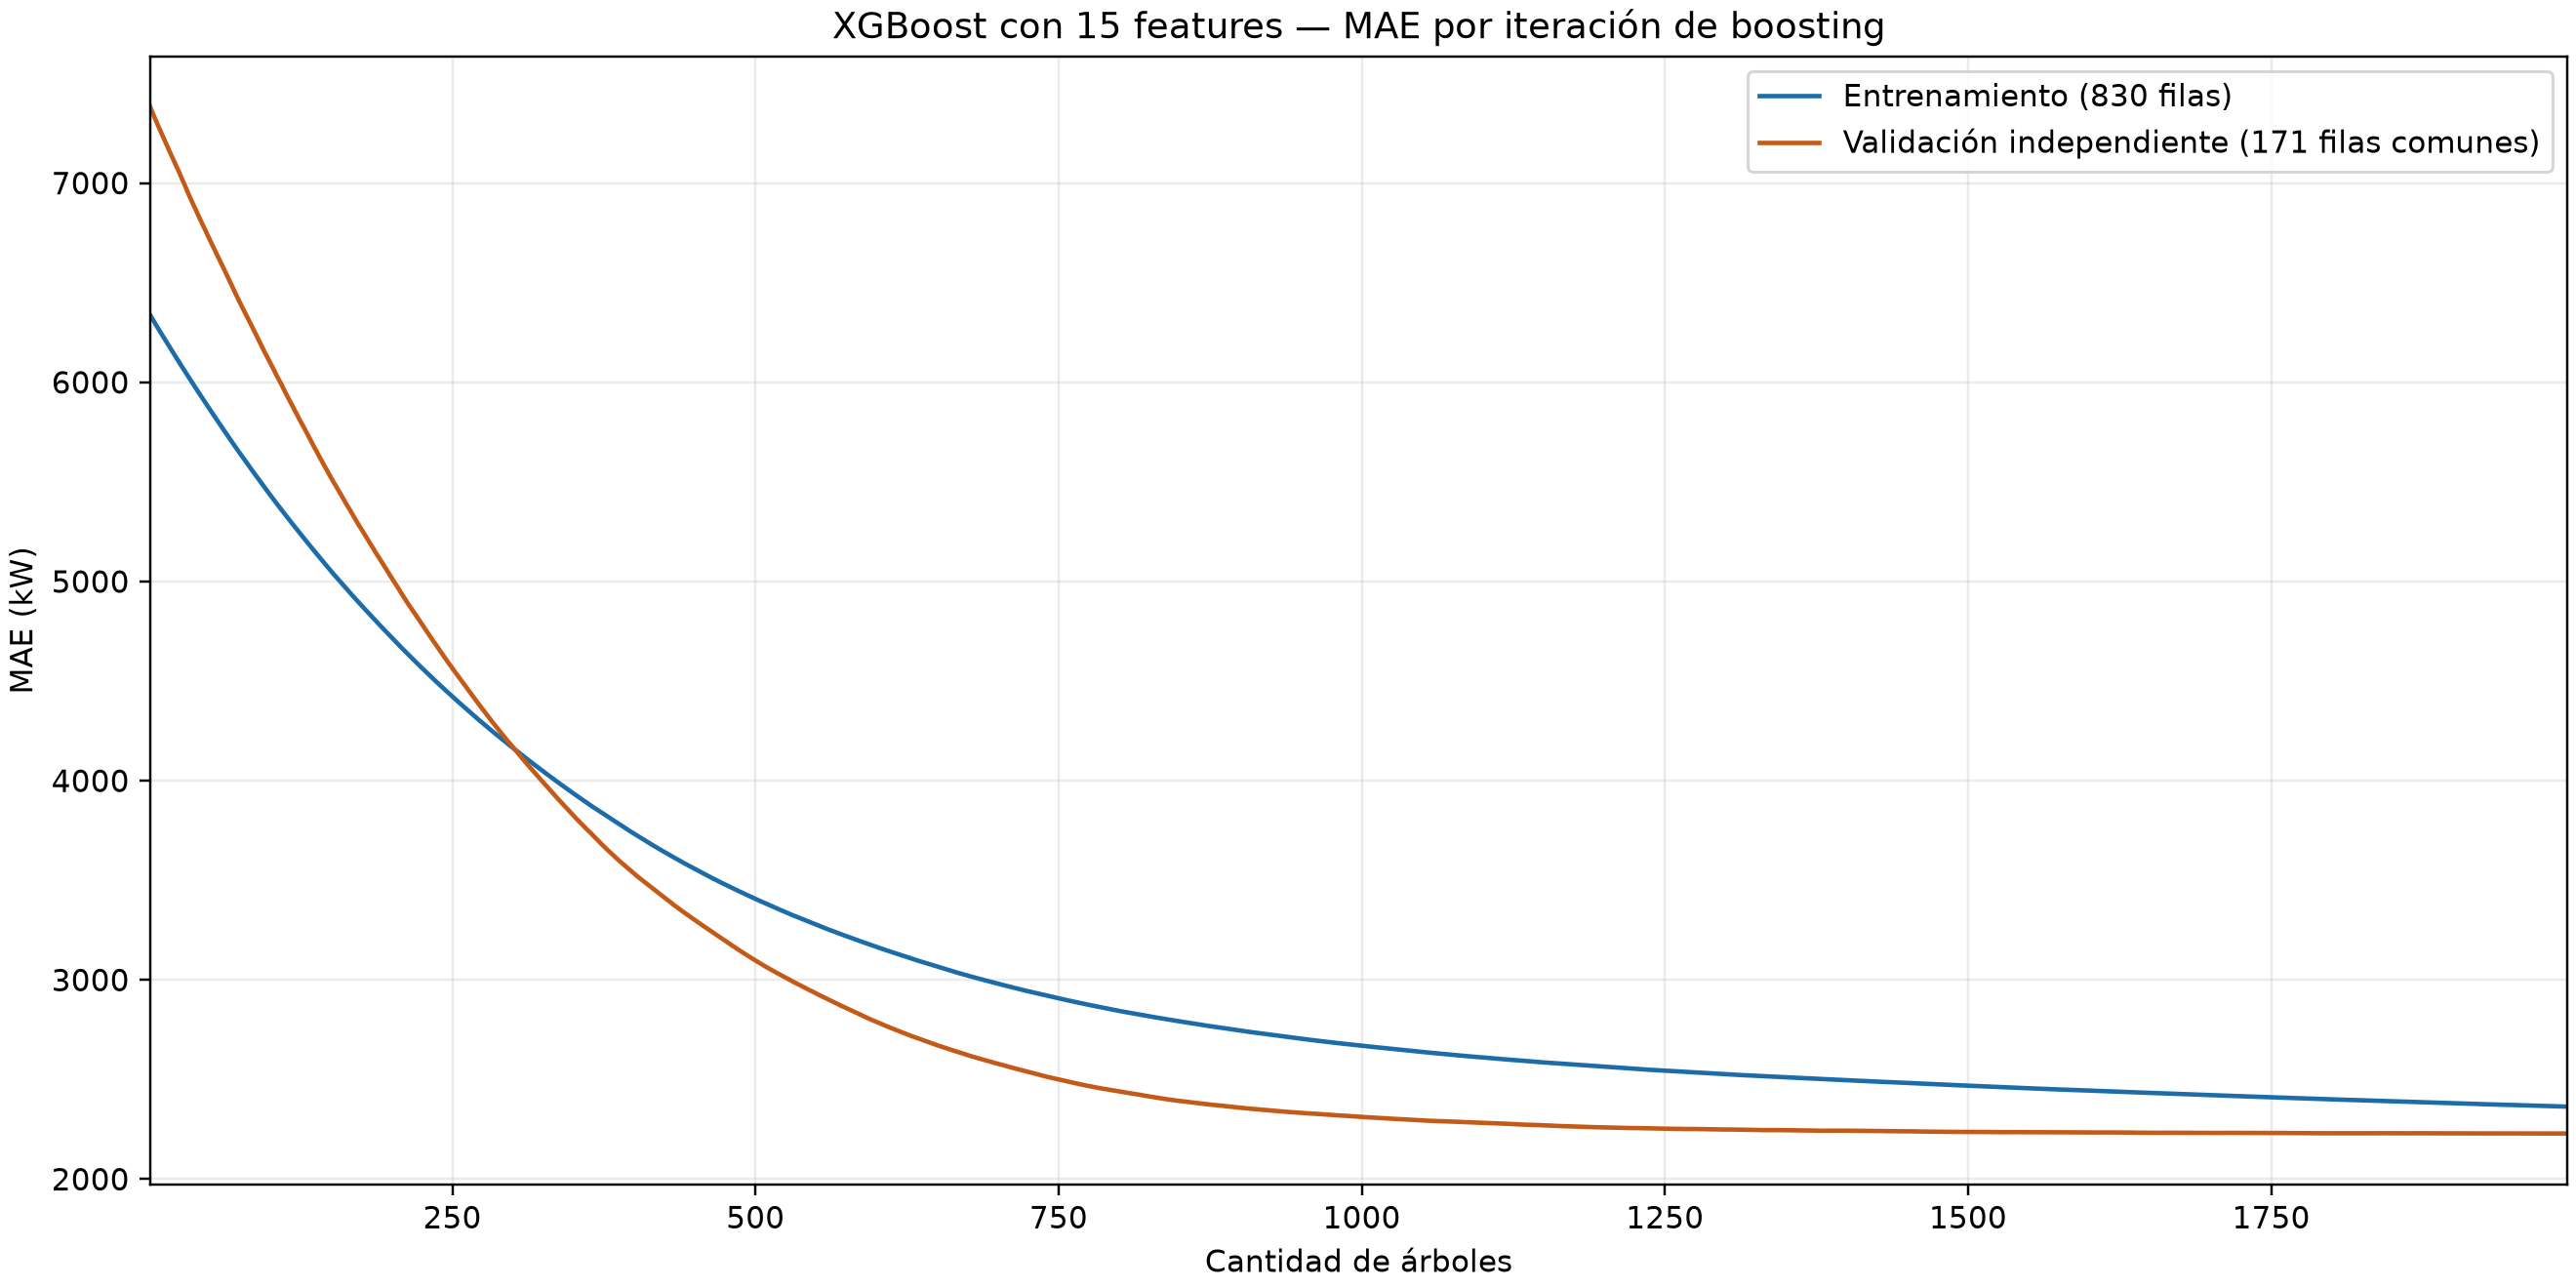

In [2]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

raiz_curvas = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz_curvas / "src"))
from auxiliar_functions import tabla_simple
from evaluar_xgboost_refinado_curvas import evaluar_con_curvas

resultado_curvas = evaluar_con_curvas()
print("Tabla 20. Configuración completa de XGBoost fijada antes de evaluar validación")
display(tabla_simple(pd.Series(resultado_curvas["configuracion_completa"], name="Valor").to_frame()))
print("Tabla 21. MAE de validación independiente del ganador refinado")
display(tabla_simple(pd.DataFrame([{
    "Trial": resultado_curvas["trial"], "Filas de entrenamiento": resultado_curvas["filas_ajuste"],
    "Filas comunes de validación": resultado_curvas["filas_validacion"],
    "Árboles entrenados": resultado_curvas["arboles_entrenados"],
    "MAE de validación (kW)": resultado_curvas["registro"]["mae"],
}])))
display(Image(filename=str(raiz_curvas / resultado_curvas["png"])))